# Análise de Dados e Matriz de Correlação - Diabetes 130-US Hospitals
Este notebook realiza o carregamento do dataset, tratamento dos códigos de diagnóstico (ICD-9 para ICD-10), **análise estatística detalhada das variáveis selecionadas** e a geração do **mapa de correlação filtrado apenas para as variáveis solicitadas**.

In [1]:
# ==============================================================================
# 1. IMPORTAÇÃO DE BIBLIOTECAS E CONFIGURAÇÕES INICIAIS
# ==============================================================================
# !pip install -q kagglehub  # Descomentar se necessário

import os
import warnings
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Silenciar avisos de depreciação de bibliotecas
warnings.filterwarnings('ignore')

# Configuração estética global dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 100

In [2]:
# ==============================================================================
# 2. CARREGAMENTO DO DATASET VIA KAGGLEHUB
# ==============================================================================
print("Carregando o dataset Diabetes 130-US hospitals...")
path = kagglehub.dataset_download("brandao/diabetes")
csv_path = os.path.join(path, "diabetic_data.csv")

df = pd.read_csv(csv_path)
print(f"Dataset carregado com sucesso! Dimensões: {df.shape[0]} linhas x {df.shape[1]} colunas.\n")

Carregando o dataset Diabetes 130-US hospitals...
Dataset carregado com sucesso! Dimensões: 101766 linhas x 50 colunas.



In [ ]:
print("=== LISTA DE COLUNAS ===")
for col in df.columns:
    print(f"- {col}")

# 2. Informação sobre tipos de dados e valores não nulos
print("\n=== INFORMAÇÃO GERAL ===")
df.info()

=== LISTA DE COLUNAS ===
- encounter_id
- patient_nbr
- race
- gender
- age
- weight
- admission_type_id
- discharge_disposition_id
- admission_source_id
- time_in_hospital
- payer_code
- medical_specialty
- num_lab_procedures
- num_procedures
- num_medications
- number_outpatient
- number_emergency
- number_inpatient
- diag_1
- diag_2
- diag_3
- number_diagnoses
- max_glu_serum
- A1Cresult
- metformin
- repaglinide
- nateglinide
- chlorpropamide
- glimepiride
- acetohexamide
- glipizide
- glyburide
- tolbutamide
- pioglitazone
- rosiglitazone
- acarbose
- miglitol
- troglitazone
- tolazamide
- examide
- citoglipton
- insulin
- glyburide-metformin
- glipizide-metformin
- glimepiride-pioglitazone
- metformin-rosiglitazone
- metformin-pioglitazone
- change
- diabetesMed
- readmitted
- icd10_diagnosis

=== INFORMAÇÃO GERAL ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 51 columns):
 #   Column                    Non-Null Count   Dtype

In [3]:
# ==============================================================================
# 3. MAPEAMENTO ICD-9 PARA ICD-10
# ==============================================================================
def convert_icd9_to_icd10_chapter(code):
    if pd.isna(code) or code == '?':
        return 'R99'
    code_str = str(code).strip()
    if code_str.startswith('V'):
        return 'Z00-Z99'
    if code_str.startswith('E'):
        return 'V01-Y98'
    try:
        val = float(code_str)
    except ValueError:
        return 'R99'

    if 140 <= val <= 239:
        return 'C00-D48'
    elif np.floor(val) == 250:
        return 'E11'
    elif 240 <= val <= 279:
        return 'E00-E89'
    elif 280 <= val <= 289:
        return 'D50-D89'
    elif 290 <= val <= 319:
        return 'F01-F99'
    elif 320 <= val <= 389:
        return 'G00-G99'
    elif (390 <= val <= 459) or val == 785:
        return 'I00-I99'
    elif (460 <= val <= 519) or val == 786:
        return 'J00-J99'
    elif (520 <= val <= 579) or val == 787:
        return 'K00-K95'
    elif (580 <= val <= 629) or val == 788:
        return 'N00-N99'
    elif 630 <= val <= 679:
        return 'O00-O9A'
    elif 680 <= val <= 709:
        return 'L00-L99'
    elif 710 <= val <= 739:
        return 'M00-M99'
    elif 740 <= val <= 759:
        return 'Q00-Q99'
    elif 780 <= val <= 799:
        return 'R00-R99'
    elif 800 <= val <= 999:
        return 'S00-T88'
    else:
        return 'R99'

icd9_to_icd10_exact = {
    '250.0': 'E11.9', '428': 'I50.9', '401': 'I10',
    '486': 'J18.9', '599': 'N39.0', '414': 'I25.10',
    '786': 'R07.9', '410': 'I21.9', '496': 'J44.9'
}

df['icd10_diagnosis'] = df['diag_1'].map(icd9_to_icd10_exact).fillna(
    df['diag_1'].apply(convert_icd9_to_icd10_chapter)
)
print("Mapeamento ICD-10 finalizado.")

Mapeamento ICD-10 finalizado.


In [4]:
# ==============================================================================
# 4. ANÁLISE ESTATÍSTICA DAS VARIÁVEIS SELECIONADAS
# ==============================================================================
cols_solicitadas = [
    'time_in_hospital', 
    'num_medications', 
    'num_lab_procedures', 
    'num_procedures', 
    'number_diagnoses'
]

nomes_amigaveis = {
    'time_in_hospital': 'Dias no Hospital',
    'num_medications': 'Nº de Medicamentos',
    'num_lab_procedures': 'Nº Exames Lab.',
    'num_procedures': 'Nº Procedimentos',
    'number_diagnoses': 'Nº de Diagnósticos'
}

# Tabela descritiva das variáveis especificadas
resumo_stats = df[cols_solicitadas].describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
resumo_stats.columns = ['Média', 'Desv. Padrão', 'Mínimo', 'Q1 (25%)', 'Mediana (50%)', 'Q3 (75%)', 'Máximo']
resumo_stats.index = [nomes_amigaveis[c] for c in resumo_stats.index]

print("=== RESUMO ESTATÍSTICO DAS VARIÁVEIS SELECIONADAS ===")
display(resumo_stats)

=== RESUMO ESTATÍSTICO DAS VARIÁVEIS SELECIONADAS ===


,Média,Desv. Padrão,Mínimo,Q1 (25%),Mediana (50%),Q3 (75%),Máximo
Dias no Hospital,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0
Nº de Medicamentos,16.021844,8.127566,1.0,10.0,15.0,20.0,81.0
Nº Exames Lab.,43.095641,19.674362,1.0,31.0,44.0,57.0,132.0
Nº Procedimentos,1.339730,1.705807,0.0,0.0,1.0,2.0,6.0
Nº de Diagnósticos,7.422607,1.933600,1.0,6.0,8.0,9.0,16.0


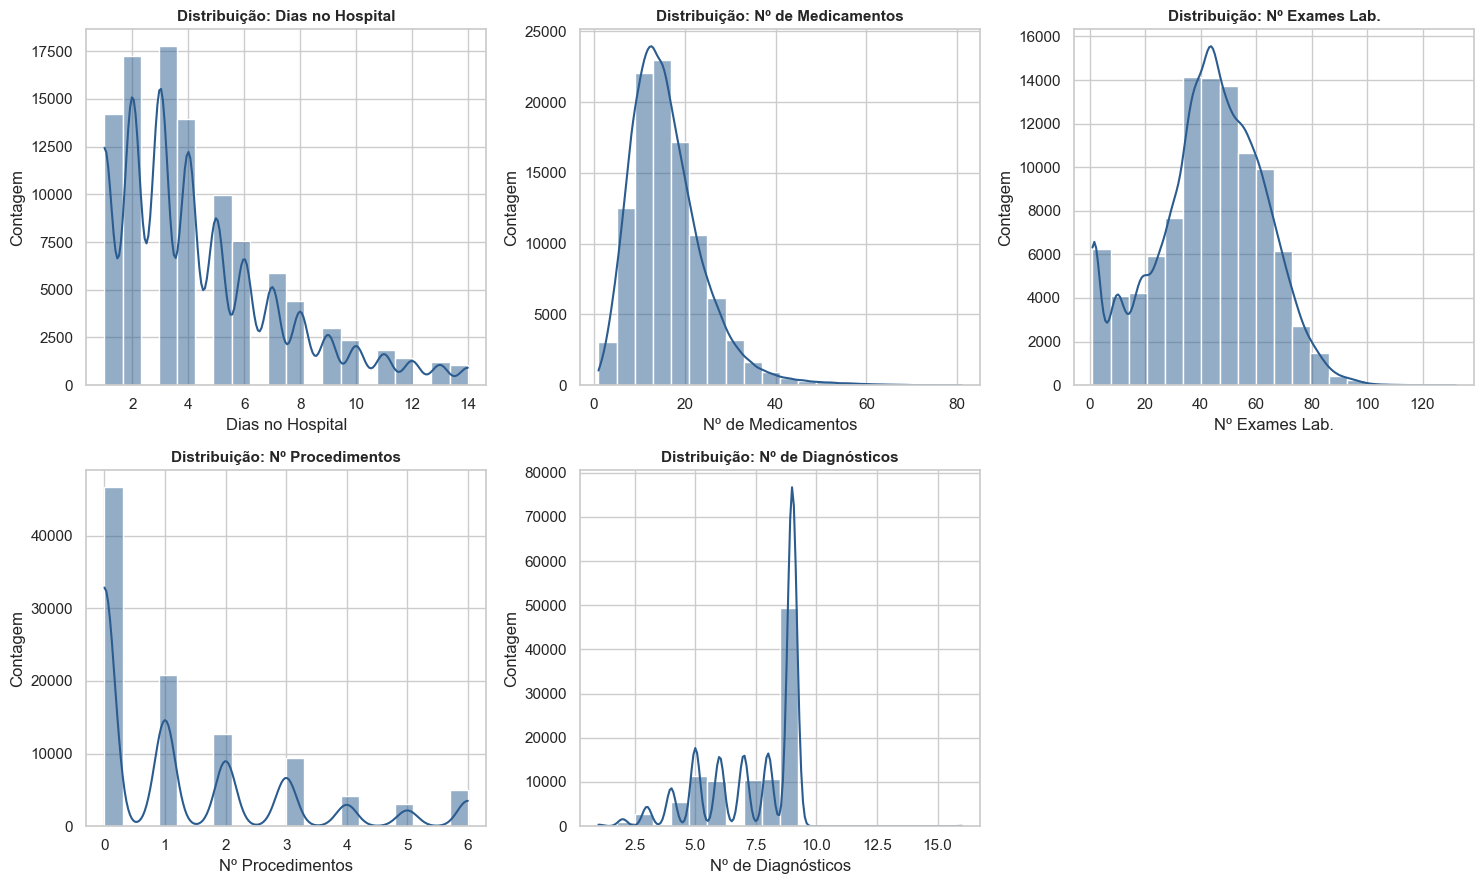

In [5]:
# Visualização Gráfica das Histograma e Densidade
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, col in enumerate(cols_solicitadas):
    sns.histplot(df[col], kde=True, ax=axes[i], color='#2b5c8f', bins=20)
    axes[i].set_title(f'Distribuição: {nomes_amigaveis[col]}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel(nomes_amigaveis[col])
    axes[i].set_ylabel('Contagem')

# Remover subplot extra sobressalente
fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

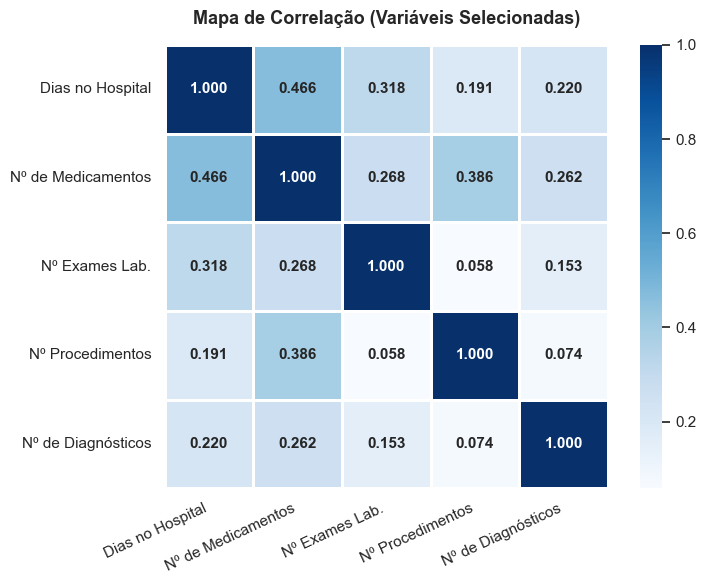

In [6]:
# ==============================================================================
# 5. MAPA DE CORRELAÇÃO (HEATMAP) - APENAS VARIÁVEIS SELECIONADAS
# ==============================================================================
# Matriz de correlação de Pearson entre as 5 variáveis especificadas
corr = df[cols_solicitadas].rename(columns=nomes_amigaveis).corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr, 
    annot=True, 
    fmt=".3f", 
    cmap="Blues", 
    cbar=True, 
    square=True, 
    linewidths=1, 
    linecolor='white',
    annot_kws={"size": 11, "weight": "bold"}
)

plt.title('Mapa de Correlação (Variáveis Selecionadas)', fontsize=13, fontweight='bold', pad=15)
plt.xticks(rotation=25, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
# ==============================================================================
# 6. EXPORTAR DATASET COM DIAGNÓSTICOS PROCESSADOS PARA DOWNLOAD
# ==============================================================================
output_csv = "diabetic_data_processed_icd10.csv"
df.to_csv(output_csv, index=False)
print(f"Ficheiro CSV exportado com sucesso: '{output_csv}'")

Ficheiro CSV exportado com sucesso: 'diabetic_data_processed_icd10.csv'
